# Dense 3DGS render: basic-arch analysis (garden)

DRAM traffic and GlobalBuffer (GLB) occupancy of the FFM-mapper results for the dense 3DGS render
workloads (`3dgs_examples/`, from 3DGSArchSpace.pptx p.2 workload / p.3 arch), swept over GLB size.

| group | workload | what it is |
|---|---|---|
| alpha compute | `workloads/dense/alpha_compute/garden.yaml` | `Alpha[v,g,pu,pv] = f(G2D[v,g])` alone |
| alpha blend | `workloads/dense/alpha_blend/garden.yaml` | `I[v,pu,pv] = blend(Alpha, F2D[v,g])` alone |
| alpha compute + alpha blend | both of the above, run back to back | unfused: Alpha goes through DRAM |
| render (fusion) | `workloads/dense/render/garden.yaml` | both Einsums in one cascade; Alpha stays on chip |

Arch: `arches/3dgs_render.yaml` (DRAM → GlobalBuffer → {ComputeAlphaArray ×256, ComputeBlendArray ×256}).
Mapping results: `3dgs_examples/mappings/dense/<workload>/garden/glb_<bytes>.{yaml,svg}` and
`summary_garden.json`, produced by `3dgs_examples/run_dense_mapping.py` (set `RERUN = True` below to
regenerate them).

GLB occupancy is taken two ways and cross-checked:
1. **mapper** — the per-tensor `usage/memory/GlobalBuffer/<tensor>` reservation the mapper reports
   (`glb_occupancy_bytes` in the summary);
2. **LoopTree walk** — re-derived from the mapping YAML: walk the loop nest, every loop narrows its rank
   to `tile_shape`, and at each `GlobalBuffer` Storage node a tensor's footprint is
   Π(current extent of its projection ranks) × bits_per_value.

In [1]:
import json, subprocess, sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import yaml

# accelforge repo root (this notebook lives in notebooks/3dgs/dense/)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "3dgs_examples").is_dir())
EX = ROOT / "3dgs_examples"
DENSE = EX / "mappings" / "dense"
SCENE = "garden"
RERUN = False  # True: re-run the FFM mapper sweep (~10 s) before analysing

if RERUN:
    subprocess.run([sys.executable, "-u", "3dgs_examples/run_dense_mapping.py", "--scene", SCENE],
                   cwd=ROOT, check=True)

summary = json.loads((DENSE / f"summary_{SCENE}.json").read_text())
GLBS = sorted(r["glb_bytes"] for r in summary["render"])
WORKLOADS = ["alpha_compute", "alpha_blend", "render"]
GROUPS = {"alpha_compute": "alpha compute", "alpha_blend": "alpha blend",
          "pair": "alpha compute + alpha blend", "render": "render (fusion)"}
TENSORS = ["Alpha", "G2D", "F2D", "I"]

def kib(b):
    return f"{b // 1024} KiB" if b < 1 << 20 else f"{b // (1 << 20)} MiB"

row = {wl: {r["glb_bytes"]: r for r in summary[wl]} for wl in WORKLOADS}
print("GLB sizes:", [kib(g) for g in GLBS])

GLB sizes: ['64 KiB', '256 KiB', '1 MiB']


## LoopTree walk: GLB footprint per tensor from the mapping YAMLs

Rank sizes and tensor projections / bits are those of `workloads/dense/*/garden.yaml`
(Nv=185 views, Ng=1,041,334 Gaussians, 622×960 pixels, Alpha 32 b).

In [2]:
RANKS = {"v": 185, "g": 1041334, "pu": 622, "pv": 960}
PROJ = {"G2D": ["v", "g"], "F2D": ["v", "g"], "I": ["v", "pu", "pv"], "Alpha": ["v", "g", "pu", "pv"]}
BITS = {"G2D": 192, "F2D": 96, "I": 128, "Alpha": 32}

class _Loader(yaml.SafeLoader):
    pass
_Loader.add_multi_constructor("!", lambda l, tag, node: {"_type": tag, **l.construct_mapping(node, deep=True)})

def glb_footprints(nodes, extent=None, out=None):
    """Bytes each tensor occupies in GlobalBuffer at its Storage node (max over branches)."""
    extent = dict(extent or RANKS)
    out = {} if out is None else out
    for n in nodes:
        t = n["_type"]
        if t in ("Temporal", "Spatial"):
            extent[n["rank_variable"]] = min(extent[n["rank_variable"]], n["tile_shape"])
        elif t == "Storage" and n["component"] == "GlobalBuffer":
            for ten in n["tensors"]:
                size = 1
                for r in PROJ[ten]:
                    size *= extent[r]
                out[ten] = max(out.get(ten, 0), size * BITS[ten] / 8)
        elif t in ("Sequential", "Nested", "Pipeline"):
            if t == "Sequential" or t == "Pipeline":
                for child in n["nodes"]:  # each branch starts from the same extents
                    glb_footprints(child["nodes"] if child["_type"] == "Nested" else [child], extent, out)
            else:
                glb_footprints(n["nodes"], extent, out)
    return out

walk = {}
for wl in WORKLOADS:
    for g in GLBS:
        m = yaml.load((DENSE / wl / SCENE / f"glb_{g}.yaml").read_text(), Loader=_Loader)
        walk[wl, g] = glb_footprints(m["mapping"]["nodes"])

check = pd.DataFrame([
    {"workload": wl, "GLB": kib(g), "tensor": t,
     "LoopTree walk (B)": walk[wl, g].get(t, 0.0),
     "mapper (B)": row[wl][g]["glb_occupancy_bytes"].get(t, 0.0)}
    for wl in WORKLOADS for g in GLBS for t in TENSORS
    if walk[wl, g].get(t) or row[wl][g]["glb_occupancy_bytes"].get(t)])
check["match"] = (check["LoopTree walk (B)"] - check["mapper (B)"]).abs() < 1e-6
assert check["match"].all(), check[~check["match"]]
check

,workload,GLB,tensor,LoopTree walk (B),mapper (B),match
0,alpha_compute,64 KiB,G2D,24.0,24.0,True
1,alpha_compute,256 KiB,G2D,24.0,24.0,True
2,alpha_compute,1 MiB,G2D,24.0,24.0,True
3,alpha_blend,64 KiB,F2D,168.0,168.0,True
4,alpha_blend,64 KiB,I,59712.0,59712.0,True
5,alpha_blend,256 KiB,F2D,168.0,168.0,True
6,alpha_blend,256 KiB,I,238848.0,238848.0,True
7,alpha_blend,1 MiB,F2D,168.0,168.0,True
8,alpha_blend,1 MiB,I,955392.0,955392.0,True
9,render,64 KiB,Alpha,13440.0,13440.0,True


## Workload: index ranges and tensors

Rank ranges and each tensor's indices / bits per value, rendered from `3dgs_examples/workloads/dense/<workload>/garden.yaml`.

In [3]:
# Index ranges and tensors, read from the workload YAMLs themselves (Jinja defaults rendered)
import jinja2

def load_workload(wl):
    text = (EX / "workloads" / "dense" / wl / f"{SCENE}.yaml").read_text()
    return yaml.safe_load(jinja2.Template(text).render())["workload"]

wls = {wl: load_workload(wl) for wl in WORKLOADS}
space = wls["render"]["iteration_space_shape"]  # superset: both Einsums
MEANING = {"v": "view (camera)", "g": "Gaussian", "pu": "pixel row", "pv": "pixel column"}

def rank_size(bound):  # "0 <= v < 185" -> 185
    return int(bound.split("<")[-1])

ranks_df = pd.DataFrame([
    {"index": r, "meaning": MEANING.get(r, ""), "range": f"[0, {rank_size(b):,})", "size": rank_size(b)}
    for r, b in space.items()])

tensors = {}
for wl, w in wls.items():
    for e in w["einsums"]:
        for ta in e["tensor_accesses"]:
            t = tensors.setdefault(ta["name"], {"proj": ta["projection"], "bits": ta["bits_per_value"],
                                                "produced": set(), "consumed": set(), "workloads": []})
            (t["produced"] if ta.get("output") else t["consumed"]).add(e["name"])
            if wl not in t["workloads"]:
                t["workloads"].append(wl)

def role(t):
    if t["produced"] and t["consumed"]:
        return "intermediate (fused in render)"
    return "output" if t["produced"] else "input"

tensor_rows = []
for name, t in tensors.items():
    n = 1
    for r in t["proj"]:
        n *= rank_size(space[r])
    tensor_rows.append({
        "tensor": f"{name}[{', '.join(t['proj'])}]",
        "role": role(t),
        "producer": ", ".join(sorted(t["produced"])) or "-",
        "consumer(s)": ", ".join(sorted(t["consumed"])) or "-",
        "bits / value": t["bits"],
        "elements": n,
        "total size (GB)": n * t["bits"] / 8 / 1e9,
        "workloads": ", ".join(t["workloads"]),
    })
tensors_df = pd.DataFrame(tensor_rows)

# the LoopTree walk above hard-codes these: keep it honest
assert RANKS == {r: rank_size(b) for r, b in space.items()}
assert PROJ == {k: v["proj"] for k, v in tensors.items()}
assert BITS == {k: v["bits"] for k, v in tensors.items()}

display(ranks_df.style.format({"size": "{:,}"}).hide(axis="index"))
display(tensors_df.style.format({"elements": "{:,}", "total size (GB)": "{:,.3f}"}).hide(axis="index"))

index,meaning,range,size
v,view (camera),"[0, 185)",185
g,Gaussian,"[0, 1,041,334)","1,041,334"
pu,pixel row,"[0, 622)",622
pv,pixel column,"[0, 960)",960


tensor,role,producer,consumer(s),bits / value,elements,total size (GB),workloads
"G2D[v, g]",input,-,ComputeAlpha,192,"192,646,790",4.624,"alpha_compute, render"
"Alpha[v, g, pu, pv]",intermediate (fused in render),ComputeAlpha,ComputeBlend,32,"115,033,251,244,800","460,133.005","alpha_compute, alpha_blend, render"
"F2D[v, g]",input,-,ComputeBlend,96,"192,646,790",2.312,"alpha_blend, render"
"I[v, pu, pv]",output,ComputeBlend,-,128,"110,467,200",1.767,"alpha_blend, render"


## GLB occupancy breakdown (% of GLB capacity)

The **alpha compute + alpha blend** group runs the two unfused stages back to back; they never hold
the buffer at the same time, so each tensor is shown at its peak over the two stages (G2D from alpha
compute, F2D / I from alpha blend) — the union of both stages' tiles, an upper bound. Unfused Alpha
streams DRAM ↔ array and is never placed in the GLB.

In [4]:
occ = {wl: {g: row[wl][g]["glb_occupancy_bytes"] for g in GLBS} for wl in WORKLOADS}
occ["pair"] = {g: {t: max(occ["alpha_compute"][g].get(t, 0.0), occ["alpha_blend"][g].get(t, 0.0))
                   for t in TENSORS} for g in GLBS}

occ_pct = pd.DataFrame([
    {"group": GROUPS[k], "GLB": kib(g),
     **{t: 100 * occ[k][g].get(t, 0.0) / g for t in TENSORS}}
    for k in GROUPS for g in GLBS])
occ_pct["total"] = occ_pct[TENSORS].sum(axis=1)
occ_pct["unused"] = 100 - occ_pct["total"]
occ_pct.style.format({c: "{:.2f}" for c in TENSORS + ["total", "unused"]}).hide(axis="index")

group,GLB,Alpha,G2D,F2D,I,total,unused
alpha compute,64 KiB,0.00,0.04,0.00,0.00,0.04,99.96
alpha compute,256 KiB,0.00,0.01,0.00,0.00,0.01,99.99
alpha compute,1 MiB,0.00,0.00,0.00,0.00,0.00,100.00
alpha blend,64 KiB,0.00,0.00,0.26,91.11,91.37,8.63
alpha blend,256 KiB,0.00,0.00,0.06,91.11,91.18,8.82
alpha blend,1 MiB,0.00,0.00,0.02,91.11,91.13,8.87
alpha compute + alpha blend,64 KiB,0.00,0.04,0.26,91.11,91.41,8.59
alpha compute + alpha blend,256 KiB,0.00,0.01,0.06,91.11,91.19,8.81
alpha compute + alpha blend,1 MiB,0.00,0.00,0.02,91.11,91.13,8.87
render (fusion),64 KiB,20.51,0.51,0.26,46.88,68.15,31.85


## DRAM traffic per run

In [5]:
dram = {wl: [row[wl][g]["dram_bytes"] for g in GLBS] for wl in WORKLOADS}
dram["pair"] = [a + b for a, b in zip(dram["alpha_compute"], dram["alpha_blend"])]
pd.DataFrame({GROUPS[k]: [d / 1e9 for d in dram[k]] for k in GROUPS},
             index=[kib(g) for g in GLBS]).rename_axis("GLB").style.format("{:,.1f} GB")

,alpha compute,alpha blend,alpha compute + alpha blend,render (fusion)
GLB,,,,
64 KiB,"460,137.6 GB","460,504.7 GB","920,642.3 GB","2,158.6 GB"
256 KiB,"460,137.6 GB","460,227.2 GB","920,364.9 GB",279.2 GB
1 MiB,"460,137.6 GB","460,157.9 GB","920,295.5 GB",71.1 GB


## Plots

In [6]:
SURFACE, INK, INK2, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#e1e0d9", "#c3c2b7"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
TCOLOR = dict(zip(TENSORS, SERIES))
GCOLOR = dict(zip(GROUPS, SERIES))

def style(ax):
    ax.set_facecolor(SURFACE)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    for s in ("left", "bottom"):
        ax.spines[s].set_color(AXIS)
    ax.tick_params(colors=INK2, labelsize=9)
    ax.grid(axis="y", color=GRID, linewidth=0.6)
    ax.set_axisbelow(True)

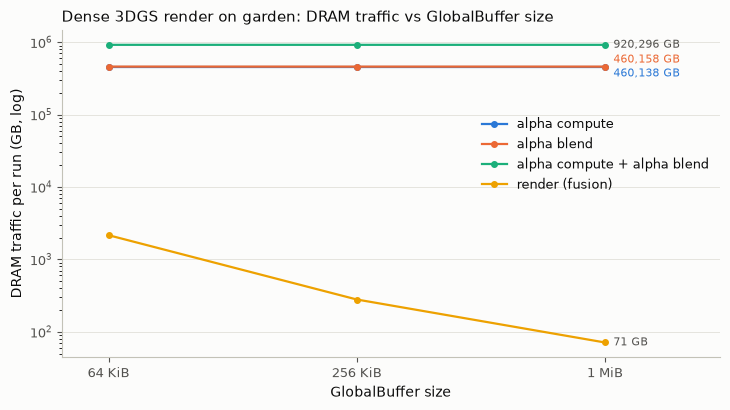

In [7]:
# Plot 1: DRAM traffic vs GLB size
fig, ax = plt.subplots(figsize=(7.4, 4.2), facecolor=SURFACE)
style(ax)
for k, label in GROUPS.items():
    y = [d / 1e9 for d in dram[k]]
    ax.plot(GLBS, y, marker="o", markersize=4, linewidth=1.6, color=GCOLOR[k], label=label)
    nudge = {"alpha_compute": -5, "alpha_blend": 5}.get(k, 0)  # these two overlap within 0.01%
    ax.annotate(f"{y[-1]:,.0f} GB", (GLBS[-1], y[-1]), xytext=(6, nudge), textcoords="offset points",
                va="center", fontsize=8, color=GCOLOR[k] if nudge else INK2)
ax.set_xscale("log", base=2)
ax.set_yscale("log")
ax.set_xticks(GLBS, [kib(g) for g in GLBS])
ax.set_xlim(GLBS[0] / 1.3, GLBS[-1] * 1.9)
ax.set_xlabel("GlobalBuffer size", color=INK)
ax.set_ylabel("DRAM traffic per run (GB, log)", color=INK)
ax.set_title(f"Dense 3DGS render on {SCENE}: DRAM traffic vs GlobalBuffer size",
             color=INK, fontsize=11, loc="left")
ax.legend(frameon=False, fontsize=9, labelcolor=INK, loc="center right", bbox_to_anchor=(1.0, 0.62))
fig.tight_layout()
plt.show()

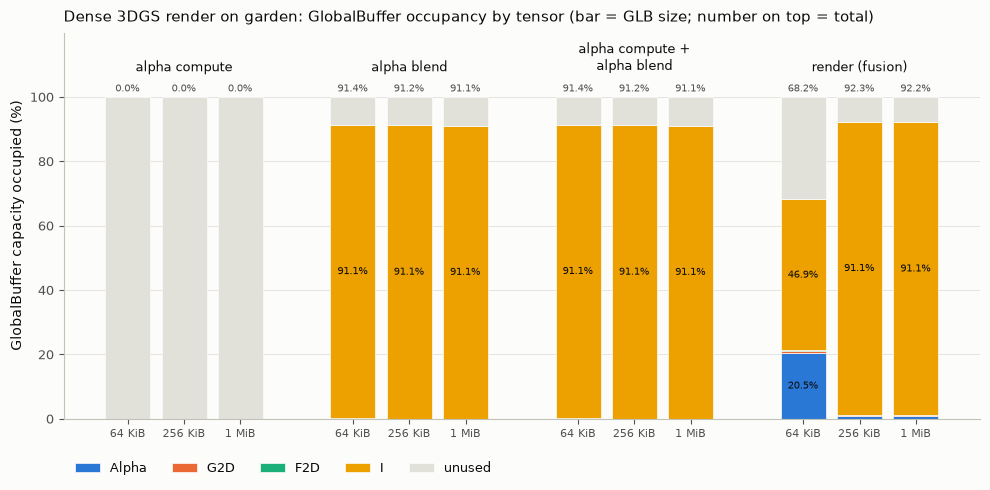

In [8]:
# Plot 2: GLB occupancy breakdown, 4 groups x one stacked bar per GLB size
fig, ax = plt.subplots(figsize=(10, 5), facecolor=SURFACE)
style(ax)
xs, xlabels = [], []
for gi, k in enumerate(GROUPS):
    for bi, g in enumerate(GLBS):
        x = gi * (len(GLBS) + 1) + bi
        xs.append(x); xlabels.append(kib(g))
        bottom = 0.0
        for t in TENSORS:
            pct = 100 * occ[k][g].get(t, 0.0) / g
            ax.bar(x, pct, 0.8, bottom=bottom, color=TCOLOR[t], edgecolor=SURFACE, linewidth=0.5,
                   label=t if (gi, bi) == (0, 0) else None)
            if pct >= 6:
                ax.text(x, bottom + pct / 2, f"{pct:.1f}%", ha="center", va="center", fontsize=7.5, color=INK)
            bottom += pct
        ax.bar(x, 100 - bottom, 0.8, bottom=bottom, color=GRID, edgecolor=SURFACE, linewidth=0.5,
               label="unused" if (gi, bi) == (0, 0) else None)
        ax.text(x, 101, f"{bottom:.1f}%", ha="center", va="bottom", fontsize=7, color=INK2)
    ax.text(gi * (len(GLBS) + 1) + (len(GLBS) - 1) / 2, 107, GROUPS[k].replace(" + ", " +\n"),
            ha="center", va="bottom", fontsize=9.5, color=INK)
ax.set_xticks(xs, xlabels, fontsize=8)
ax.set_ylim(0, 120)
ax.set_yticks(range(0, 101, 20))
ax.set_ylabel("GlobalBuffer capacity occupied (%)", color=INK)
ax.set_title(f"Dense 3DGS render on {SCENE}: GlobalBuffer occupancy by tensor (bar = GLB size; "
             "number on top = total)", color=INK, fontsize=11, loc="left", pad=8)
ax.legend(frameon=False, fontsize=9, labelcolor=INK, ncol=5, loc="upper left", bbox_to_anchor=(0, -0.08))
fig.tight_layout()
plt.show()
# exact per-segment percentages (G2D / F2D are too thin to label on the bars)
occ_pct.pivot_table(index="group", columns="GLB", values=TENSORS, sort=False)[TENSORS] \
    .reindex(columns=[kib(g) for g in GLBS], level=1).style.format("{:.2f}")

## LoopTree viewer

Set `WORKLOAD` and `GLB` (or call `show_looptree(workload, glb)` directly) to load that mapping's LoopTree SVG from `3dgs_examples/mappings/dense/<workload>/garden/glb_<bytes>.svg`.

**alpha compute, GLB 64 KiB** -- `3dgs_examples/mappings/dense/alpha_compute/garden/glb_65536.svg` (YAML: `3dgs_examples/mappings/dense/alpha_compute/garden/glb_65536.yaml`)  
DRAM 460,137.6 GB, energy 4.226e+04 J, GLB occupancy: G2D 0.04%

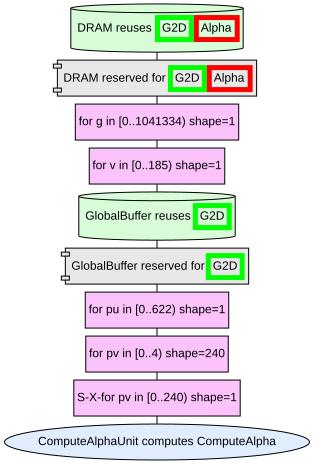

In [9]:
# LoopTree viewer: pick a config and the mapper's LoopTree SVG for it is shown below.
# WORKLOAD: "alpha_compute" | "alpha_blend" | "render"
# GLB:      bytes (65536) or "64KiB" / "256KiB" / "1MiB" -- one of the swept sizes in GLBS
WORKLOAD = "alpha_compute"
GLB = "64KiB"

from IPython.display import SVG, Markdown

def parse_glb(glb):
    if isinstance(glb, int):
        return glb
    s = glb.replace(" ", "").lower()
    for unit, mult in (("kib", 1 << 10), ("mib", 1 << 20), ("b", 1)):
        if s.endswith(unit):
            return int(float(s[: -len(unit)]) * mult)
    return int(s)

def show_looptree(workload=WORKLOAD, glb=GLB):
    if workload not in WORKLOADS:
        raise ValueError(f"workload must be one of {WORKLOADS}, got {workload!r}")
    g = parse_glb(glb)
    if g not in GLBS:
        raise ValueError(f"GLB {glb!r} = {g} B was not swept; available: {[kib(x) for x in GLBS]}")
    svg = DENSE / workload / SCENE / f"glb_{g}.svg"
    r = row[workload][g]
    occ_str = ", ".join(f"{t} {100 * b / g:.2f}%" for t, b in r["glb_occupancy_bytes"].items()) or "-"
    display(Markdown(
        f"**{GROUPS[workload]}, GLB {kib(g)}** -- `{svg.relative_to(ROOT)}` "
        f"(YAML: `{svg.with_suffix('.yaml').relative_to(ROOT)}`)  \n"
        f"DRAM {r['dram_bytes'] / 1e9:,.1f} GB, energy {r['energy_J']:,.4g} J, GLB occupancy: {occ_str}"))
    display(SVG(filename=str(svg)))

show_looptree(WORKLOAD, GLB)

## Takeaways

- **I dominates the GLB whenever it is buffered (~91 %).** The mapper spends the GLB on a growing
  pixel strip of I (622 × 24 px at 256 KiB, 622 × 96 px at 1 MiB, 16 B/px), while the G2D / F2D tiles
  stay at 14 Gaussians (336 B / 168 B), so their share falls as the buffer grows (G2D 0.51 → 0.13 → 0.03 %,
  F2D 0.26 → 0.06 → 0.02 % in the fused render).
- **Fused render at 64 KiB is the exception:** the outer loop splits pixel *rows* (pu/2, 311 trips), so I
  is only 2 × 960 px (30 KB, 46.9 %) and the on-chip Alpha tile (14 g × 120 pv × 2 pu × 4 B ≈ 13 KB, 20.5 %)
  is visible; from 256 KiB on, Alpha is ~1 %.
- **Unfused stages:** Alpha never enters the GLB (it is streamed DRAM ↔ array and has no reuse there), so
  alpha compute holds just one 24 B G2D entry and the pair is bounded by alpha blend's I strip.
- **DRAM:** fusion keeps Alpha (460 TB per run) on chip; the fused render's traffic then falls with GLB
  size (2,159 → 279 → 71 GB) because a larger I strip cuts the G2D / F2D refetch factor (311 → 40 → 10),
  while the unfused stages stay flat at ~460,000 GB each (920,296 GB for the pair).